In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bjoernjostein/wolfparkinsonwhitedata")

print("Path to dataset files:", path)


100%|██████████████████████████████████████████████████████████████████████████████| 39.4M/39.4M [00:32<00:00, 1.28MB/s]

Extracting files...


Path to dataset files: /home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1


In [11]:
import os

DATASET_PATH = "/home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1"

os.listdir(DATASET_PATH)



['wpw_dataset']

COMPLETE WPW DATASET DEEP DIVE - EVERYTHING YOU NEED TO KNOW

PART 1: .MAT FILES (MATLAB FORMAT) - THE RAW ECG SIGNALS

Total .mat files: 160

📊 DETAILED ANALYSIS OF: JS36160.mat
--------------------------------------------------------------------------------

1️⃣  ALL KEYS IN .MAT FILE:
   val: (THIS IS THE ECG SIGNAL DATA)

2️⃣  RAW SIGNAL STRUCTURE:
   Key name: 'val'
   Data type: <class 'numpy.ndarray'>
   Shape: (12, 5000)
   Dimensions: 2D array
   Data type: int16
   ⚠️  Transposed to: (5000, 12)

3️⃣  SIGNAL DETAILS:
   📏 Number of samples: 5000
   📡 Number of leads/channels: 12
   ⏱️  Duration: 10.00 seconds (@ 500 Hz)
   🔢 Value range: [-2098.00, 2206.00]
   📊 Mean value: -2.18
   📈 Std deviation: 256.25

4️⃣  ECG LEADS (Standard 12-lead ECG):
   Lead I  : Range=[ -171.00,   854.00], Mean=    4.53, Std= 154.77
   Lead II : Range=[ -278.00,   874.00], Mean=    5.33, Std= 184.94
   Lead III: Range=[ -439.00,   571.00], Mean=    0.81, Std= 106.35
   Lead aVR: Range=[ -776.00,  

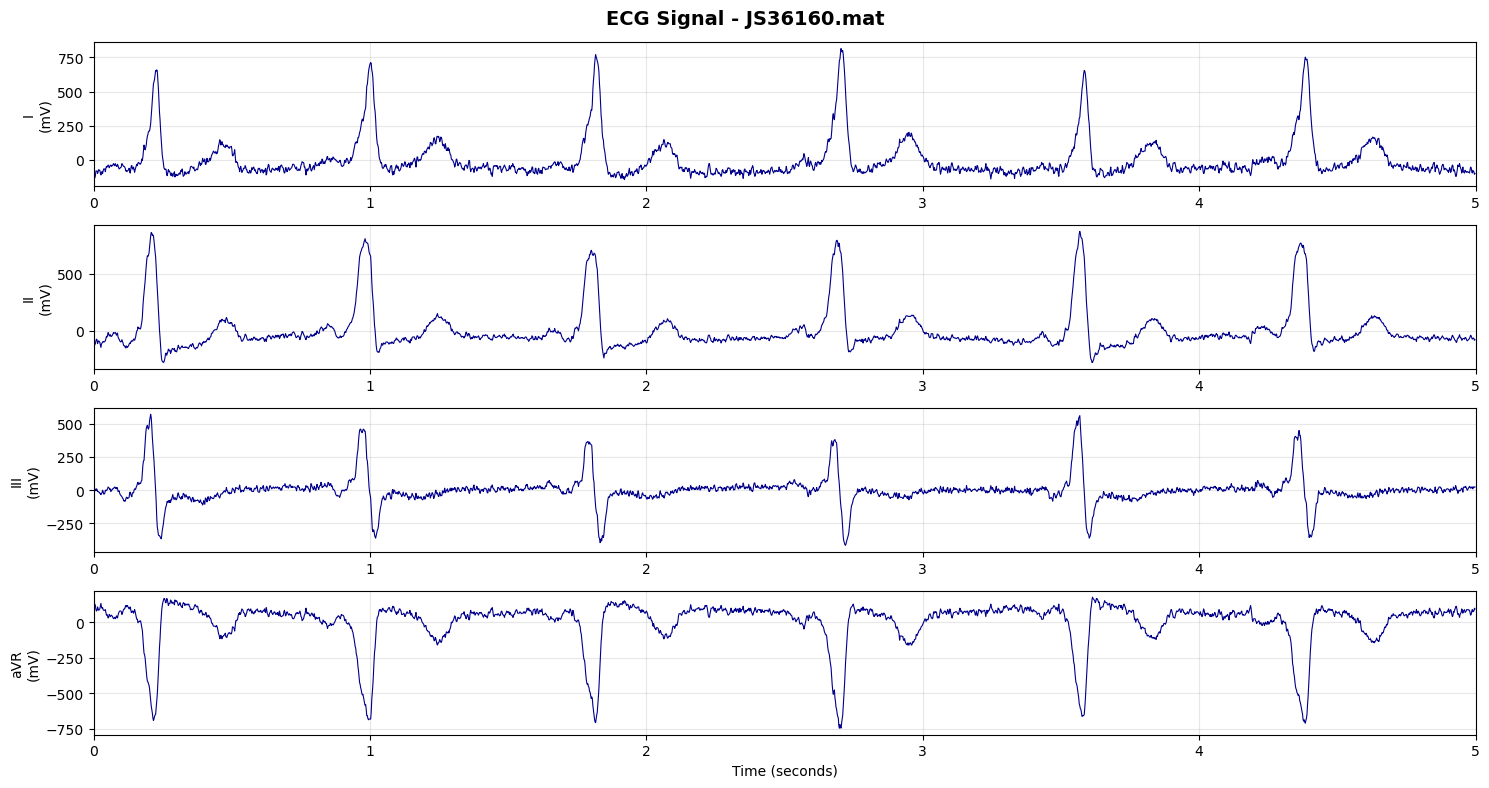


PART 2: .HEA FILES (HEADER FILES) - METADATA & ANNOTATIONS

Total .hea files: 160

📄 DETAILED ANALYSIS OF FIRST 3 HEADER FILES:
--------------------------------------------------------------------------------

1. FILE: JS10034.hea
   ----------------------------------------------------------------------------
   Total lines: 19

   FULL CONTENT:
   Line 1: JS10034 12 500 5000 24-Mar-2021 07:17:24
   Line 2: JS10034.mat 16+24 1000/mV 16 0 200 -23246 0 I
   Line 3: JS10034.mat 16+24 1000/mV 16 0 -29 11057 0 II
   Line 4: JS10034.mat 16+24 1000/mV 16 0 -229 -31226 0 III
   Line 5: JS10034.mat 16+24 1000/mV 16 0 -83 -20614 0 aVR
   Line 6: JS10034.mat 16+24 1000/mV 16 0 215 30701 0 aVL
   Line 7: JS10034.mat 16+24 1000/mV 16 0 -132 -16206 0 aVF
   Line 8: JS10034.mat 16+24 1000/mV 16 0 -508 8318 0 V1
   Line 9: JS10034.mat 16+24 1000/mV 16 0 -195 -6775 0 V2
   Line 10: JS10034.mat 16+24 1000/mV 16 0 205 -3064 0 V3
   Line 11: JS10034.mat 16+24 1000/mV 16 0 307 -18517 0 V4
   Line 12: JS10

In [16]:
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
import matplotlib.pyplot as plt

# =========================
# CONFIGURATION
# =========================
BASE_PATH = "/home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1/wpw_dataset"

print("="*80)
print("COMPLETE WPW DATASET DEEP DIVE - EVERYTHING YOU NEED TO KNOW")
print("="*80)

# =========================
# PART 1: WHAT'S IN .MAT FILES?
# =========================
print("\n" + "="*80)
print("PART 1: .MAT FILES (MATLAB FORMAT) - THE RAW ECG SIGNALS")
print("="*80)

mat_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".mat")]
print(f"\nTotal .mat files: {len(mat_files)}")

# Analyze first .mat file in detail
if len(mat_files) > 0:
    sample_mat = mat_files[0]
    print(f"\n📊 DETAILED ANALYSIS OF: {sample_mat}")
    print("-" * 80)
    
    filepath = os.path.join(BASE_PATH, sample_mat)
    data = loadmat(filepath)
    
    print("\n1️⃣  ALL KEYS IN .MAT FILE:")
    for key in data.keys():
        if key.startswith("__"):
            print(f"   {key}: (metadata, ignore)")
        else:
            print(f"   {key}: (THIS IS THE ECG SIGNAL DATA)")
    
    # Get the signal data
    signal_keys = [k for k in data.keys() if not k.startswith("__")]
    
    if signal_keys:
        signal_key = signal_keys[0]
        raw_signal = data[signal_key]
        
        print(f"\n2️⃣  RAW SIGNAL STRUCTURE:")
        print(f"   Key name: '{signal_key}'")
        print(f"   Data type: {type(raw_signal)}")
        print(f"   Shape: {raw_signal.shape}")
        print(f"   Dimensions: {raw_signal.ndim}D array")
        print(f"   Data type: {raw_signal.dtype}")
        
        # Fix transpose if needed
        if raw_signal.shape[1] > raw_signal.shape[0]:
            raw_signal = raw_signal.T
            print(f"   ⚠️  Transposed to: {raw_signal.shape}")
        
        n_samples, n_channels = raw_signal.shape
        
        print(f"\n3️⃣  SIGNAL DETAILS:")
        print(f"   📏 Number of samples: {n_samples}")
        print(f"   📡 Number of leads/channels: {n_channels}")
        print(f"   ⏱️  Duration: {n_samples / 500:.2f} seconds (@ 500 Hz)")
        print(f"   🔢 Value range: [{np.min(raw_signal):.2f}, {np.max(raw_signal):.2f}]")
        print(f"   📊 Mean value: {np.mean(raw_signal):.2f}")
        print(f"   📈 Std deviation: {np.std(raw_signal):.2f}")
        
        print(f"\n4️⃣  ECG LEADS (Standard 12-lead ECG):")
        lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
        
        for i in range(min(n_channels, 12)):
            lead_name = lead_names[i] if i < len(lead_names) else f"Lead_{i+1}"
            lead_data = raw_signal[:, i]
            print(f"   Lead {lead_name:3s}: Range=[{np.min(lead_data):8.2f}, {np.max(lead_data):8.2f}], "
                  f"Mean={np.mean(lead_data):8.2f}, Std={np.std(lead_data):7.2f}")
        
        print(f"\n5️⃣  SAMPLE DATA (First 10 samples, Lead II):")
        print(f"   {raw_signal[:10, 1] if n_channels > 1 else raw_signal[:10, 0]}")
        
        # Visualize multiple leads
        print(f"\n6️⃣  VISUALIZING ECG SIGNALS...")
        fig, axes = plt.subplots(min(4, n_channels), 1, figsize=(15, 8))
        if n_channels == 1:
            axes = [axes]
        
        time = np.arange(min(2500, n_samples)) / 500  # First 5 seconds
        
        for i in range(min(4, n_channels)):
            lead_name = lead_names[i] if i < len(lead_names) else f"Lead_{i+1}"
            signal_segment = raw_signal[:min(2500, n_samples), i]
            
            axes[i].plot(time, signal_segment, linewidth=0.8, color='darkblue')
            axes[i].set_ylabel(f'{lead_name}\n(mV)', fontsize=10)
            axes[i].grid(True, alpha=0.3)
            axes[i].set_xlim(0, 5)
            
            if i == min(4, n_channels) - 1:
                axes[i].set_xlabel('Time (seconds)', fontsize=10)
        
        fig.suptitle(f'ECG Signal - {sample_mat}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('wpw_raw_signal_analysis.png', dpi=300, bbox_inches='tight')
        print(f"   ✅ Saved visualization as 'wpw_raw_signal_analysis.png'")
        plt.show()

# =========================
# PART 2: WHAT'S IN .HEA FILES?
# =========================
print("\n" + "="*80)
print("PART 2: .HEA FILES (HEADER FILES) - METADATA & ANNOTATIONS")
print("="*80)

hea_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".hea")]
print(f"\nTotal .hea files: {len(hea_files)}")

if len(hea_files) > 0:
    print(f"\n📄 DETAILED ANALYSIS OF FIRST 3 HEADER FILES:")
    print("-" * 80)
    
    for idx, hea_file in enumerate(hea_files[:3]):
        filepath = os.path.join(BASE_PATH, hea_file)
        
        print(f"\n{idx+1}. FILE: {hea_file}")
        print("   " + "-" * 76)
        
        with open(filepath, 'r') as f:
            lines = f.readlines()
            
        print(f"   Total lines: {len(lines)}")
        print(f"\n   FULL CONTENT:")
        for line_num, line in enumerate(lines, 1):
            print(f"   Line {line_num}: {line.rstrip()}")
        
        # Parse header information
        print(f"\n   PARSED INFORMATION:")
        if len(lines) > 0:
            # First line typically contains: record_name num_signals sampling_freq num_samples
            first_line = lines[0].split()
            if len(first_line) >= 3:
                print(f"   - Record name: {first_line[0]}")
                print(f"   - Number of signals: {first_line[1]}")
                print(f"   - Sampling frequency: {first_line[2]} Hz")
                if len(first_line) > 3:
                    print(f"   - Number of samples: {first_line[3]}")
        
        # Check for diagnosis/labels
        diagnosis_found = False
        for line in lines:
            lower_line = line.lower()
            if any(keyword in lower_line for keyword in ['wpw', 'syndrome', 'diagnosis', 'normal', 'abnormal']):
                print(f"   🏷️  LABEL/DIAGNOSIS FOUND: {line.rstrip()}")
                diagnosis_found = True
        
        if not diagnosis_found:
            print(f"   ⚠️  No obvious diagnosis/label found")

# =========================
# PART 3: EXTRACTED FEATURES EXPLAINED
# =========================
print("\n" + "="*80)
print("PART 3: EXTRACTED FEATURES - WHAT EACH ONE MEANS CLINICALLY")
print("="*80)

features_explanation = {
    "record_id": {
        "type": "Identifier",
        "description": "Unique identifier for each ECG record",
        "clinical_significance": "Used to track and reference specific patient recordings"
    },
    "num_r_peaks": {
        "type": "Count",
        "description": "Total number of R-peaks detected in the ECG",
        "clinical_significance": "More R-peaks = more heartbeats. Used to validate signal quality",
        "normal_range": "Depends on duration, ~60-100 beats/min"
    },
    "signal_duration": {
        "type": "Time (seconds)",
        "description": "Total length of the ECG recording",
        "clinical_significance": "Longer recordings provide more data for analysis",
        "typical_values": "10 seconds (standard) to several minutes"
    },
    "hr_mean": {
        "type": "Heart Rate (bpm)",
        "description": "Average heart rate throughout the recording",
        "clinical_significance": "🔴 KEY FEATURE: WPW patients often have tachycardia (fast heart rate)",
        "normal_range": "60-100 bpm",
        "wpw_pattern": "Often >100 bpm (tachycardia) or irregular"
    },
    "hr_std": {
        "type": "Heart Rate Variability (bpm)",
        "description": "Standard deviation of heart rate",
        "clinical_significance": "High values indicate irregular rhythm - common in WPW",
        "normal_range": "<10 bpm",
        "wpw_pattern": "May be elevated due to arrhythmias"
    },
    "hr_min": {
        "type": "Heart Rate (bpm)",
        "description": "Minimum heart rate detected",
        "clinical_significance": "Helps identify bradycardia episodes",
        "normal_range": ">50 bpm"
    },
    "hr_max": {
        "type": "Heart Rate (bpm)",
        "description": "Maximum heart rate detected",
        "clinical_significance": "🔴 KEY FEATURE: WPW can cause sudden rapid heart rates (SVT)",
        "normal_range": "<120 bpm at rest",
        "wpw_pattern": "Can exceed 200 bpm during SVT episodes"
    },
    "hrv_sdnn": {
        "type": "Time (milliseconds)",
        "description": "Standard Deviation of NN intervals (time between normal heartbeats)",
        "clinical_significance": "🔴 KEY FEATURE: Measures heart rate variability",
        "normal_range": "20-100 ms",
        "wpw_pattern": "Abnormal due to irregular conduction pathway"
    },
    "hrv_rmssd": {
        "type": "Time (milliseconds)",
        "description": "Root Mean Square of Successive Differences between heartbeats",
        "clinical_significance": "🔴 KEY FEATURE: Sensitive to beat-to-beat changes",
        "normal_range": "20-50 ms",
        "wpw_pattern": "Altered due to accessory pathway"
    },
    "hrv_pnn50": {
        "type": "Percentage (%)",
        "description": "% of successive RR intervals that differ by >50ms",
        "clinical_significance": "Measures parasympathetic nervous system activity",
        "normal_range": "5-50%",
        "wpw_pattern": "May be abnormal"
    },
    "qrs_duration_ms": {
        "type": "Time (milliseconds)",
        "description": "Average duration of QRS complex (ventricular depolarization)",
        "clinical_significance": "🔴 🔴 MOST IMPORTANT FOR WPW: Delta wave widens QRS",
        "normal_range": "80-120 ms",
        "wpw_pattern": ">120 ms (WIDENED due to delta wave) ⚠️"
    },
    "qrs_amplitude": {
        "type": "Voltage (mV)",
        "description": "Average height of QRS complex",
        "clinical_significance": "🔴 KEY FEATURE: May be altered in WPW",
        "normal_range": "5-20 mV",
        "wpw_pattern": "Can be abnormally high or low"
    },
    "signal_mean": {
        "type": "Voltage (mV)",
        "description": "Average voltage across entire signal",
        "clinical_significance": "Baseline reference, should be near zero",
        "normal_range": "~0 mV"
    },
    "signal_std": {
        "type": "Voltage (mV)",
        "description": "Standard deviation of signal voltage",
        "clinical_significance": "Measures overall signal variability",
        "typical_values": "0.5-2.0 mV"
    },
    "signal_min": {
        "type": "Voltage (mV)",
        "description": "Minimum voltage (most negative deflection)",
        "clinical_significance": "Captures S-wave depth",
        "typical_values": "-1 to -3 mV"
    },
    "signal_max": {
        "type": "Voltage (mV)",
        "description": "Maximum voltage (most positive deflection)",
        "clinical_significance": "Captures R-wave peak",
        "typical_values": "1 to 3 mV"
    },
    "signal_range": {
        "type": "Voltage (mV)",
        "description": "Difference between max and min voltage",
        "clinical_significance": "Total signal amplitude span",
        "typical_values": "2-6 mV"
    },
    "signal_skewness": {
        "type": "Statistical measure",
        "description": "Asymmetry of the signal distribution",
        "clinical_significance": "Indicates if waveform is symmetric",
        "normal_range": "Near 0 (symmetric)"
    },
    "signal_kurtosis": {
        "type": "Statistical measure",
        "description": "Peakedness of the signal distribution",
        "clinical_significance": "Measures how sharp the peaks are",
        "normal_range": "~3 (normal distribution)"
    }
}

print("\n📚 FEATURE DICTIONARY:")
print("-" * 80)

for feature_name, details in features_explanation.items():
    print(f"\n🔹 {feature_name.upper()}")
    print(f"   Type: {details['type']}")
    print(f"   Description: {details['description']}")
    print(f"   Clinical Significance: {details['clinical_significance']}")
    if 'normal_range' in details:
        print(f"   Normal Range: {details['normal_range']}")
    if 'wpw_pattern' in details:
        print(f"   ⚠️  WPW Pattern: {details['wpw_pattern']}")
    if 'typical_values' in details:
        print(f"   Typical Values: {details['typical_values']}")

# =========================
# PART 4: WPW SYNDROME EXPLANATION
# =========================
print("\n" + "="*80)
print("PART 4: WOLFF-PARKINSON-WHITE (WPW) SYNDROME - MEDICAL EXPLANATION")
print("="*80)

wpw_info = """
🏥 WHAT IS WPW SYNDROME?
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

WPW is a heart condition where there's an EXTRA electrical pathway between the 
atria and ventricles (called the "Bundle of Kent" or "accessory pathway").

🫀 NORMAL HEART:
   Atria → AV Node (delay) → Bundle of His → Ventricles
   
⚡ WPW HEART:
   Atria → AV Node → Ventricles  ✅ Normal pathway
   Atria → ACCESSORY PATHWAY → Ventricles  ⚠️ Extra shortcut!


🔍 ECG CHARACTERISTICS OF WPW:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. 🔴 SHORT PR INTERVAL (<120 ms)
   - Normal: 120-200 ms
   - WPW: <120 ms (signal bypasses AV node delay)

2. 🔴 DELTA WAVE (slurred upstroke of QRS)
   - Early ventricular activation via accessory pathway
   - Creates a "bump" at start of QRS complex

3. 🔴 WIDE QRS COMPLEX (>120 ms)
   - Normal: 80-120 ms
   - WPW: >120 ms due to delta wave

4. 🔴 SECONDARY ST-T WAVE CHANGES
   - Abnormal repolarization pattern


⚠️ CLINICAL DANGERS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. SUPRAVENTRICULAR TACHYCARDIA (SVT)
   - Heart rate can suddenly jump to >200 bpm
   - Re-entry circuit forms using the accessory pathway

2. ATRIAL FIBRILLATION RISK
   - Can lead to dangerously fast ventricular rates
   - Risk of sudden cardiac death if untreated

3. PALPITATIONS & DIZZINESS
   - Patients feel rapid heartbeat
   - Can cause fainting (syncope)


🎯 FEATURES THAT DISTINGUISH WPW:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

MOST IMPORTANT:
  ✅ qrs_duration_ms > 120 ms (WIDENED QRS)
  ✅ hr_max > 150 bpm (TACHYCARDIA episodes)
  ✅ hrv_sdnn abnormal (IRREGULAR rhythm)
  ✅ qrs_amplitude altered (DELTA WAVE effect)

SUPPORTING:
  ✅ hr_mean elevated
  ✅ hr_std high variability
  ✅ hrv_rmssd abnormal
"""

print(wpw_info)

# =========================
# PART 5: FEATURE IMPORTANCE RANKING
# =========================
print("\n" + "="*80)
print("PART 5: FEATURE IMPORTANCE FOR WPW DETECTION (RANKED)")
print("="*80)

importance_ranking = [
    ("🥇 #1", "qrs_duration_ms", "CRITICAL - Delta wave widens QRS >120ms"),
    ("🥈 #2", "hr_max", "Very important - SVT episodes with high HR"),
    ("🥉 #3", "qrs_amplitude", "Important - Delta wave affects amplitude"),
    ("4️⃣", "hrv_sdnn", "Important - Rhythm irregularity marker"),
    ("5️⃣", "hrv_rmssd", "Important - Beat-to-beat variability"),
    ("6️⃣", "hr_mean", "Moderate - Overall tachycardia trend"),
    ("7️⃣", "hr_std", "Moderate - Rhythm stability"),
    ("8️⃣", "hrv_pnn50", "Moderate - Autonomic function"),
    ("9️⃣", "signal_range", "Supportive - Waveform amplitude"),
    ("🔟", "signal_std", "Supportive - Signal variability"),
]

print("\n📊 RANKED BY DIAGNOSTIC VALUE:")
for rank, feature, reason in importance_ranking:
    print(f"{rank:4s} {feature:20s} → {reason}")

# =========================
# SUMMARY
# =========================
print("\n" + "="*80)
print("SUMMARY - FILES STRUCTURE")
print("="*80)

print("""
📁 .MAT FILES:
   - Contains: RAW ECG SIGNALS (12-lead voltage data)
   - Format: NumPy array [samples × leads]
   - Each sample: Voltage reading at 1/500th second
   - Used for: All signal processing and feature extraction

📁 .HEA FILES:
   - Contains: METADATA (sampling rate, duration, leads info)
   - Format: Plain text
   - May contain: Diagnosis, patient info, annotations
   - Used for: Understanding recording parameters + LABELS

🔬 EXTRACTED FEATURES:
   - Derived from .mat files through signal processing
   - 19 features per record
   - Ready for machine learning
   - Most important: QRS duration, HR max, HRV metrics
""")

print("\n" + "="*80)
print("✅ ANALYSIS COMPLETE!")
print("="*80)
print("\nYou now understand:")
print("  ✓ What's in .mat files (raw signals)")
print("  ✓ What's in .hea files (metadata)")
print("  ✓ What each extracted feature means")
print("  ✓ Which features are most important for WPW")
print("  ✓ How WPW affects the ECG")

print("="*80)

In [14]:
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.signal import find_peaks

# ===============================
# CONFIG
# ===============================
BASE_PATH = "/home/jovyan/.cache/kagglehub/datasets/bjoernjostein/wolfparkinsonwhitedata/versions/1/wpw_dataset"
OUTPUT_CSV = "wpw_dataset_features.csv"

# ===============================
# FUNCTIONS
# ===============================
def load_mat(mat_path):
    data = loadmat(mat_path)
    ecg = data['val']  # shape (12, 5000)
    return ecg.T       # transpose → (5000 x 12)

def load_hea(hea_path):
    meta = {}
    with open(hea_path, 'r') as f:
        lines = f.readlines()
    meta['record_id'] = lines[0].split()[0]
    for line in lines:
        if line.startswith("#Age:"):
            meta["age"] = int(line.split(":")[1].strip())
        elif line.startswith("#Sex:"):
            meta["sex"] = line.split(":")[1].strip()
        elif line.startswith("#Dx:"):
            meta["dx"] = line.split(":")[1].strip()
    return meta

def extract_features(ecg, fs=500):
    features = {}
    
    # Lead II for R-peaks
    lead = ecg[:, 1]
    
    # R-peak detection (min distance 0.4s)
    peaks, _ = find_peaks(lead, distance=int(0.4*fs))
    rr_intervals = np.diff(peaks)/fs
    hr = 60 / rr_intervals if len(rr_intervals) > 0 else np.array([0])
    
    # HR features
    features['hr_mean'] = np.mean(hr) if len(hr) > 0 else 0
    features['hr_std'] = np.std(hr) if len(hr) > 0 else 0
    features['hr_max'] = np.max(hr) if len(hr) > 0 else 0
    
    # HRV features
    features['hrv_sdnn'] = np.std(rr_intervals) if len(rr_intervals) > 0 else 0
    features['hrv_rmssd'] = np.sqrt(np.mean(np.diff(rr_intervals)**2)) if len(rr_intervals) > 1 else 0
    features['hrv_pnn50'] = np.sum(np.abs(np.diff(rr_intervals))>0.05)/len(rr_intervals)*100 if len(rr_intervals) > 1 else 0
    
    # QRS duration approx (half-max width)
    qrs_durations = []
    for p in peaks:
        left = p
        right = p
        while left > 0 and lead[left] > 0.5 * lead[p]:
            left -= 1
        while right < len(lead)-1 and lead[right] > 0.5 * lead[p]:
            right += 1
        qrs_durations.append((right-left)/fs*1000)
    features['qrs_duration_ms'] = np.mean(qrs_durations) if len(qrs_durations) > 0 else 0
    
    # QRS amplitude
    qrs_amp = []
    for p in peaks:
        qrs_amp.append(np.max(lead[max(0,p-5):p+5]) - np.min(lead[max(0,p-5):p+5]))
    features['qrs_amplitude'] = np.mean(qrs_amp) if len(qrs_amp) > 0 else 0
    
    # Signal stats
    features['signal_range'] = np.max(ecg) - np.min(ecg)
    features['signal_std'] = np.std(ecg)
    
    return features

# ===============================
# PROCESS ALL FILES
# ===============================
records = []
for fname in os.listdir(BASE_PATH):
    if fname.endswith(".mat"):
        record_id = fname.split(".")[0]
        mat_path = os.path.join(BASE_PATH, f"{record_id}.mat")
        hea_path = os.path.join(BASE_PATH, f"{record_id}.hea")
        
        # Load
        ecg = load_mat(mat_path)
        meta = load_hea(hea_path)
        
        # Features
        feats = extract_features(ecg)
        
        # Combine
        row = {**meta, **feats}
        records.append(row)

# ===============================
# SAVE CSV
# ===============================
df = pd.DataFrame(records)
df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved CSV: {OUTPUT_CSV}")


Saved CSV: wpw_dataset_features.csv


/tmp/ipykernel_123/3695501339.py:75: RuntimeWarning: overflow encountered in scalar subtract
  features['signal_range'] = np.max(ecg) - np.min(ecg)


In [3]:
import pandas as pd

df = pd.read_csv("wpw_dataset_features.csv")

# Quick overview
print(df.head())
print(df.info())
print(df.describe())


  record_id  age     sex                                     dx     hr_mean  \
0   JS36160   40  Female                     426783006,74390002  128.790543   
1   HR07407   47    Male  164951009,39732003,426783006,74390002   81.512301   
2   HR20486   54  Female                     426783006,74390002  136.489773   
3   HR04658   59  Female   164951009,39732003,63593006,74390002  137.265660   
4   HR15183   64    Male  164951009,39732003,426783006,74390002  142.520682   

      hr_std      hr_max  hrv_sdnn  hrv_rmssd  hrv_pnn50  qrs_duration_ms  \
0  23.574015  148.514851  0.129130   0.188542  35.000000        29.619048   
1   0.790141   83.102493  0.007080   0.007348   0.000000        31.428571   
2   9.168301  150.000000  0.030503   0.051872  31.818182        84.782609   
3   6.655315  144.927536  0.022164   0.034825  22.727273        18.260870   
4   4.838566  150.000000  0.014340   0.025726   0.000000        59.666667   

   qrs_amplitude  signal_range  signal_std  
0      83.809524 

In [4]:
df["dx"] = 1
df.to_csv("wpw_dataset_features_binary.csv", index=False)


In [6]:
import pandas as pd
import numpy as np

# ===============================
# LOAD BOTH DATASETS
# ===============================
df_only_sinus = pd.read_csv("only_sinus_cleanest_160.csv")
df_wpw = pd.read_csv("cleanestwpwp.csv")

# ===============================
# OPTIONAL: Harmonize column names
# ===============================
# Ensure both datasets have the same columns, or add missing columns with NaN/0
for col in df_only_sinus.columns:
    if col not in df_wpw.columns:
        df_wpw[col] = np.nan

for col in df_wpw.columns:
    if col not in df_only_sinus.columns:
        df_only_sinus[col] = np.nan

# Reorder columns the same way
df_only_sinus = df_only_sinus[df_wpw.columns]

# ===============================
# MERGE DATASETS
# ===============================
df_merged = pd.concat([df_wpw, df_only_sinus], ignore_index=True)

# ===============================
# SAVE MERGED CSV
# ===============================
df_merged.to_csv("merged_cleanest_ecg.csv", index=False)
print(f"Saved merged dataset: merged_cleanest_ecg.csv with {len(df_merged)} records")


Saved merged dataset: merged_cleanest_ecg.csv with 320 records


In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

# ===============================
# LOAD MERGED DATASET
# ===============================
df = pd.read_csv("merged_cleanest_ecg.csv")

# ===============================
# PREPROCESSING
# ===============================
# Encode 'sex' to 0/1
df['sex'] = df['sex'].replace({
    'Male': 1, 'M': 1, 'male': 1,
    'Female': 0, 'F': 0, 'female': 0
})

# Fill missing numeric values with median
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Optional: log-transform skewed HRV features (recommended)
for col in ["hrv_rmssd", "hrv_sdnn"]:
    if col in df.columns:
        df[col] = np.log1p(df[col])

# Features and target
X = df.drop(columns=["dx", "record_id"])
y = df["dx"]

# Ensure all features are numeric
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median())

# ===============================
# TRAIN-TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ===============================
# PIPELINE: SCALING → POLY → LOGISTIC
# ===============================
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("logreg", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

# ===============================
# HYPERPARAMETER GRID (SAFE & EFFECTIVE)
# ===============================
param_grid = {
    # Polynomial complexity
    "poly__degree": [1, 2],               # 1 = linear, 2 = interactions
    "poly__interaction_only": [False, True],

    # Regularization
    "logreg__penalty": ["l1", "l2"],
    "logreg__C": [0.001, 0.01, 0.1, 1, 10]
}

# ===============================
# GRID SEARCH
# ===============================
grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print("\n=== BEST PARAMETERS ===")
print(grid_search.best_params_)

# ===============================
# CROSS-VALIDATION (FULL DATASET)
# ===============================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_auc = cross_val_score(best_model, X, y, cv=cv, scoring="roc_auc")
cv_acc = cross_val_score(best_model, X, y, cv=cv, scoring="accuracy")

print("\nCross-validated AUC-ROC:", cv_auc)
print(f"Mean AUC-ROC: {cv_auc.mean():.4f}")

print("\nCross-validated Accuracy:", cv_acc)
print(f"Mean Accuracy: {cv_acc.mean():.4f}")

# ===============================
# TEST SET EVALUATION
# ===============================
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("\n=== TEST SET RESULTS ===")
print(f"Accuracy: {acc:.4f}")
print(f"AUC-ROC: {auc:.4f}")
print("Confusion Matrix:")
print(cm)
print("Classification Report:")
print(report)

# ===============================
# FEATURE IMPORTANCE (COEFFICIENTS)
# ===============================
logreg = best_model.named_steps["logreg"]
poly = best_model.named_steps["poly"]

feature_names = poly.get_feature_names_out(X.columns)

coef = pd.Series(
    logreg.coef_[0],
    index=feature_names
).sort_values(ascending=False)

print("\n=== TOP POSITIVE COEFFICIENTS ===")
print(coef.head(15))

print("\n=== TOP NEGATIVE COEFFICIENTS ===")
print(coef.tail(15))


Fitting 5 folds for each of 40 candidates, totalling 200 fits

=== BEST PARAMETERS ===
{'logreg__C': 1, 'logreg__penalty': 'l1', 'poly__degree': 1, 'poly__interaction_only': False}

Cross-validated AUC-ROC: [0.96972656 0.9765625  0.98339844 0.96289062 0.96484375]
Mean AUC-ROC: 0.9715

Cross-validated Accuracy: [0.9375   0.921875 0.953125 0.953125 0.953125]
Mean Accuracy: 0.9437

=== TEST SET RESULTS ===
Accuracy: 0.9688
AUC-ROC: 0.9775
Confusion Matrix:
[[32  0]
 [ 2 30]]
Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        32
           1       1.00      0.94      0.97        32

    accuracy                           0.97        64
   macro avg       0.97      0.97      0.97        64
weighted avg       0.97      0.97      0.97        64


=== TOP POSITIVE COEFFICIENTS ===
signal_std         8.295047
signal_range       1.048925
sex                0.833588
hrv_pnn50          0.063402
hr_std             0.00000

In [3]:
import pandas as pd
import numpy as np

# Load your feature CSV
df = pd.read_csv("wpw_dataset_features.csv")

# Drop non-numeric / ID / target columns
numeric_df = df.drop(columns=['record_id', 'dx'])

# Ensure all columns are numeric
numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')
numeric_df = numeric_df.fillna(numeric_df.median())

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Print numeric correlation matrix
print(corr_matrix)


                      age  sex   hr_mean    hr_std    hr_max  hrv_sdnn  \
age              1.000000  NaN -0.022689 -0.035044  0.054976 -0.082435   
sex                   NaN  NaN       NaN       NaN       NaN       NaN   
hr_mean         -0.022689  NaN  1.000000  0.202958  0.625830  0.095463   
hr_std          -0.035044  NaN  0.202958  1.000000  0.708448  0.976255   
hr_max           0.054976  NaN  0.625830  0.708448  1.000000  0.600649   
hrv_sdnn        -0.082435  NaN  0.095463  0.976255  0.600649  1.000000   
hrv_rmssd       -0.020269  NaN  0.200991  0.922180  0.618992  0.905594   
hrv_pnn50        0.145349  NaN  0.346212  0.530691  0.539417  0.412693   
qrs_duration_ms -0.005540  NaN  0.023089  0.027377  0.053918  0.020319   
qrs_amplitude   -0.203161  NaN -0.272596 -0.371195 -0.346392 -0.314381   
signal_range    -0.159131  NaN -0.032700  0.025892 -0.007132  0.017497   
signal_std       0.046489  NaN  0.103458 -0.013532  0.057914 -0.013610   

                 hrv_rmssd  hrv_pnn50